# 06 · Deep Learning for Sentiment — PyTorch
**Part of the [Sentiment Analysis on IMDB 50K](README.md) project.** Previous: [05 Classical ML](05_classical_ml_models.ipynb).

Main agenda, part 2. We build three neural networks from scratch in PyTorch on the same train/test split as notebook 05 — a fastText-style averaging model, a 1-D CNN and a bidirectional GRU — then compare them against the classical baseline.

> Runs on a plain CPU (no GPU needed). Models are kept small on purpose.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import re, time, collections, os, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
sns.set_theme(style='whitegrid')
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', DEVICE)

torch 2.14.1+cu130 | device: cpu


## 1. Data and the shared split

In [2]:
df = pd.read_csv('data/imdb_clean.csv', usecols=['review','sentiment','label','clean'])
train_idx, test_idx = train_test_split(df.index, test_size=.2, stratify=df['label'], random_state=42)
tr_idx, va_idx = train_test_split(train_idx, test_size=.1, stratify=df.loc[train_idx,'label'], random_state=42)
print('train', len(tr_idx), 'val', len(va_idx), 'test', len(test_idx))

train 35698 val 3967 test 9917


In [3]:
pd.Series({'train':df.loc[tr_idx,'label'].mean(),'val':df.loc[va_idx,'label'].mean(),'test':df.loc[test_idx,'label'].mean()}).round(3).to_frame('share positive')

,share positive
train,0.502
val,0.502
test,0.502


The test set is the **same 20%** as notebook 05, so numbers are directly comparable. We carve a validation set (10% of train) for early stopping — the test set is touched only once at the end.

## 2. Tokenisation & vocabulary

In [4]:
def tok(s): return s.split()
c = collections.Counter(w for s in df.loc[tr_idx,'clean'] for w in tok(s))   # vocab from TRAIN only (no leakage)
print('train vocabulary:', len(c))

train vocabulary: 87017


In [5]:
MAX_VOCAB=30000
itos = ['<pad>','<unk>'] + [w for w,_ in c.most_common(MAX_VOCAB-2)]
stoi = {w:i for i,w in enumerate(itos)}
covered = sum(c[w] for w in itos[2:])/sum(c.values()); print(f'vocab {len(itos):,} covers {covered*100:.1f}% of training tokens')

vocab 30,000 covers 98.7% of training tokens


In [6]:
itos[:20]

['<pad>',
 '<unk>',
 'the',
 'and',
 'a',
 'of',
 'is',
 'to',
 'it',
 'in',
 'i',
 'this',
 'that',
 'not',
 'was',
 'as',
 'movie',
 'for',
 'with',
 'but']

### 2.1 Choosing the sequence length

In [7]:
lens = df.loc[tr_idx,'clean'].str.split().str.len()
for L in [128,200,256,300,400,500]: print(f'MAX_LEN={L}: {(lens<=L).mean()*100:.1f}% of reviews fit completely')

MAX_LEN=128: 24.9% of reviews fit completely
MAX_LEN=200: 58.1% of reviews fit completely
MAX_LEN=256: 70.6% of reviews fit completely
MAX_LEN=300: 77.2% of reviews fit completely
MAX_LEN=400: 86.7% of reviews fit completely
MAX_LEN=500: 92.0% of reviews fit completely


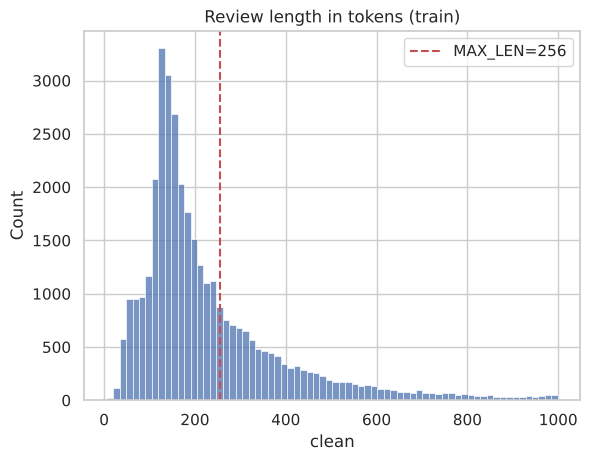

In [8]:
sns.histplot(lens[lens<1000], bins=70); plt.axvline(256,color='r',ls='--',label='MAX_LEN=256'); plt.legend(); plt.title('Review length in tokens (train)'); plt.show()

We use `MAX_LEN = 256` — a compromise between covering most reviews and CPU training time. Longer reviews are truncated, shorter ones padded.

In [9]:
MAX_LEN=256
def encode(s):
    ids = [stoi.get(w,1) for w in tok(s)][:MAX_LEN]
    return ids + [0]*(MAX_LEN-len(ids))
encode('this film was not good at all')[:12]

[11, 20, 14, 13, 51, 31, 30, 0, 0, 0, 0, 0]

In [10]:
t=time.time()
X = {name: torch.tensor([encode(s) for s in df.loc[idx,'clean']], dtype=torch.long) for name,idx in [('train',tr_idx),('val',va_idx),('test',test_idx)]}
Y = {name: torch.tensor(df.loc[idx,'label'].values, dtype=torch.float32) for name,idx in [('train',tr_idx),('val',va_idx),('test',test_idx)]}
print({k:tuple(v.shape) for k,v in X.items()}, f'{time.time()-t:.0f}s')

{'train': (35698, 256), 'val': (3967, 256), 'test': (9917, 256)} 4s


In [11]:
BS=128
loaders = {k: DataLoader(torch.utils.data.TensorDataset(X[k],Y[k]), batch_size=BS, shuffle=(k=='train')) for k in X}
xb,yb = next(iter(loaders['train'])); print(xb.shape, yb.shape)

torch.Size([128, 256]) torch.Size([128])


## 3. A reusable training loop

In [12]:
def run_epoch(model, loader, opt=None):
    train = opt is not None; model.train(train); tot_loss=0; correct=0; N=0
    with torch.set_grad_enabled(train):
        for xb,yb in loader:
            logit = model(xb); loss = F.binary_cross_entropy_with_logits(logit, yb)
            if train: opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot_loss += loss.item()*len(yb); correct += ((logit>0).float()==yb).sum().item(); N+=len(yb)
    return tot_loss/N, correct/N

def fit(model, epochs=4, lr=2e-3, patience=2, name='model'):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    hist=[]; best=(0,None); bad=0
    for ep in range(1,epochs+1):
        t=time.time(); trl,tra = run_epoch(model, loaders['train'], opt); val,vaa = run_epoch(model, loaders['val'])
        hist.append(dict(epoch=ep, train_loss=trl, train_acc=tra, val_loss=val, val_acc=vaa, sec=time.time()-t))
        print(f'{name} epoch {ep}: train_acc={tra:.4f} val_acc={vaa:.4f} val_loss={val:.4f} ({time.time()-t:.0f}s)')
        if vaa>best[0]: best=(vaa,{k:v.clone() for k,v in model.state_dict().items()}); bad=0
        else:
            bad+=1
            if bad>=patience: print('early stop'); break
    model.load_state_dict(best[1]); return pd.DataFrame(hist)

In [13]:
@torch.no_grad()
def predict_logits(model, k='test'):
    model.eval(); return torch.cat([model(xb) for xb,_ in loaders[k]]).numpy()
TEST_RESULTS={}
def report(name, model, hist=None):
    lg = predict_logits(model); pred=(lg>0).astype(int); y=Y['test'].numpy()
    TEST_RESULTS[name]=dict(accuracy=accuracy_score(y,pred), f1=f1_score(y,pred), roc_auc=roc_auc_score(y,lg), params=sum(p.numel() for p in model.parameters()), train_sec=(hist.sec.sum() if hist is not None else np.nan))
    return pd.Series(TEST_RESULTS[name]).round(4)
def plot_hist(h, title):
    fig,ax=plt.subplots(1,2,figsize=(11,3.8)); ax[0].plot(h.epoch,h.train_loss,'o-',label='train'); ax[0].plot(h.epoch,h.val_loss,'o-',label='val'); ax[0].set_title(title+' — loss'); ax[0].legend()
    ax[1].plot(h.epoch,h.train_acc,'o-',label='train'); ax[1].plot(h.epoch,h.val_acc,'o-',label='val'); ax[1].set_title(title+' — accuracy'); ax[1].legend(); plt.tight_layout(); plt.show()

## 4. Model A — fastText-style averaging network

Embed each word, **average** the embeddings (ignoring padding), then a linear layer. Order is ignored, so it is a neural cousin of bag-of-words.

In [14]:
class AvgEmbed(nn.Module):
    def __init__(self, V, d=64):
        super().__init__(); self.emb=nn.Embedding(V,d,padding_idx=0); self.drop=nn.Dropout(.3); self.fc=nn.Linear(d,1)
    def forward(self,x):
        m=(x!=0).float().unsqueeze(-1); e=self.emb(x)*m; avg=e.sum(1)/m.sum(1).clamp(min=1)
        return self.fc(self.drop(avg)).squeeze(-1)
mA=AvgEmbed(len(itos)); print(mA); print('parameters:', f'{sum(p.numel() for p in mA.parameters()):,}')

AvgEmbed(
  (emb): Embedding(30000, 64, padding_idx=0)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
parameters: 1,920,065


In [15]:
hA = fit(mA, epochs=6, lr=5e-3, name='AvgEmbed'); hA

AvgEmbed epoch 1: train_acc=0.7712 val_acc=0.8551 val_loss=0.3435 (9s)


AvgEmbed epoch 2: train_acc=0.8892 val_acc=0.8765 val_loss=0.2901 (6s)


AvgEmbed epoch 3: train_acc=0.9198 val_acc=0.8793 val_loss=0.2818 (6s)


AvgEmbed epoch 4: train_acc=0.9359 val_acc=0.8800 val_loss=0.2861 (6s)


AvgEmbed epoch 5: train_acc=0.9478 val_acc=0.8782 val_loss=0.2986 (6s)


AvgEmbed epoch 6: train_acc=0.9580 val_acc=0.8767 val_loss=0.3179 (6s)
early stop


,epoch,train_loss,train_acc,val_loss,val_acc,sec
0,1,0.493108,0.771220,0.343471,0.855054,9.074252
1,2,0.277239,0.889181,0.290125,0.876481,6.066478
2,3,0.215058,0.919799,0.281809,0.879254,6.262098
3,4,0.178705,0.935907,0.286142,0.880010,6.376380
4,5,0.150752,0.947784,0.298598,0.878246,6.075298
5,6,0.126762,0.957981,0.317906,0.876733,6.207649


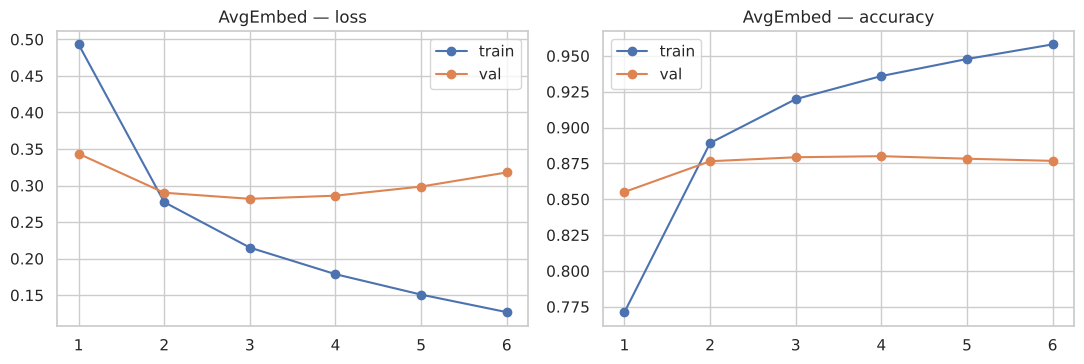

In [16]:
plot_hist(hA,'AvgEmbed')

In [17]:
report('A · AvgEmbed', mA, hA)

accuracy     8.913000e-01
f1           8.910000e-01
roc_auc      9.560000e-01
params       1.920065e+06
train_sec    4.006220e+01
dtype: float64

## 5. Model B — 1-D Convolutional network (n-gram detectors)

Convolution filters of widths 2, 3, 4, 5 slide over the word sequence — each filter learns to fire on a particular *phrase pattern* (like “waste of time”). Max-pooling keeps the strongest hit anywhere in the review.

In [18]:
class TextCNN(nn.Module):
    def __init__(self, V, d=100, nf=64, widths=(2,3,4,5), drop=.5):
        super().__init__(); self.emb=nn.Embedding(V,d,padding_idx=0)
        self.convs=nn.ModuleList([nn.Conv1d(d,nf,w) for w in widths]); self.drop=nn.Dropout(drop); self.fc=nn.Linear(nf*len(widths),1)
    def forward(self,x):
        e=self.emb(x).transpose(1,2)
        feats=[F.relu(c(e)).max(dim=2).values for c in self.convs]
        return self.fc(self.drop(torch.cat(feats,1))).squeeze(-1)
mB=TextCNN(len(itos)); print(mB); print('parameters:', f'{sum(p.numel() for p in mB.parameters()):,}')

TextCNN(
  (emb): Embedding(30000, 100, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(100, 64, kernel_size=(2,), stride=(1,))
    (1): Conv1d(100, 64, kernel_size=(3,), stride=(1,))
    (2): Conv1d(100, 64, kernel_size=(4,), stride=(1,))
    (3): Conv1d(100, 64, kernel_size=(5,), stride=(1,))
  )
  (drop): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)
parameters: 3,090,113


In [19]:
hB = fit(mB, epochs=5, lr=2e-3, name='TextCNN'); hB

TextCNN epoch 1: train_acc=0.6926 val_acc=0.8039 val_loss=0.4338 (81s)


TextCNN epoch 2: train_acc=0.8005 val_acc=0.8235 val_loss=0.3838 (77s)


TextCNN epoch 3: train_acc=0.8432 val_acc=0.8578 val_loss=0.3215 (78s)


TextCNN epoch 4: train_acc=0.8799 val_acc=0.8656 val_loss=0.3107 (78s)


TextCNN epoch 5: train_acc=0.9089 val_acc=0.8724 val_loss=0.3162 (80s)


,epoch,train_loss,train_acc,val_loss,val_acc,sec
0,1,0.575705,0.692560,0.433775,0.803882,81.392832
1,2,0.432323,0.800493,0.383770,0.823544,77.207618
2,3,0.354480,0.843213,0.321463,0.857827,77.504945
3,4,0.285746,0.879909,0.310690,0.865642,77.753900
4,5,0.226874,0.908902,0.316218,0.872448,79.598145


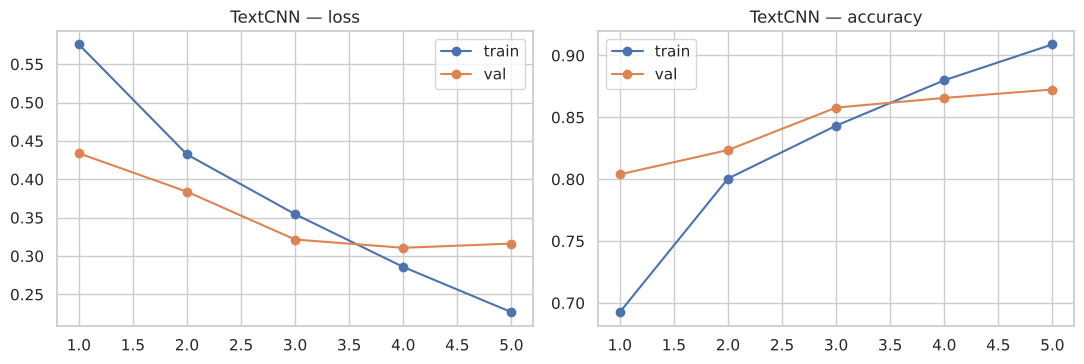

In [20]:
plot_hist(hB,'TextCNN')

In [21]:
report('B · TextCNN', mB, hB)

accuracy     8.756000e-01
f1           8.735000e-01
roc_auc      9.491000e-01
params       3.090113e+06
train_sec    3.934574e+02
dtype: float64

## 6. Model C — Bidirectional GRU

A GRU reads the review left→right and right→left, keeping a memory of context, so it can capture long-range effects (e.g. *“I expected to hate it, but …”*). We pack padding out with `lengths` so the GRU ignores it.

In [22]:
class BiGRU(nn.Module):
    def __init__(self, V, d=100, h=64, drop=.4):
        super().__init__(); self.emb=nn.Embedding(V,d,padding_idx=0); self.gru=nn.GRU(d,h,batch_first=True,bidirectional=True); self.drop=nn.Dropout(drop); self.fc=nn.Linear(2*h*2,1)
    def forward(self,x):
        mask=(x!=0); L=mask.sum(1).clamp(min=1).cpu()
        out,_=self.gru(nn.utils.rnn.pack_padded_sequence(self.emb(x),L,batch_first=True,enforce_sorted=False))
        out,_=nn.utils.rnn.pad_packed_sequence(out,batch_first=True,total_length=x.size(1))
        m=mask.unsqueeze(-1).float(); mean=(out*m).sum(1)/m.sum(1).clamp(min=1); mx=(out-1e4*(1-m)).max(1).values
        return self.fc(self.drop(torch.cat([mean,mx],1))).squeeze(-1)
mC=BiGRU(len(itos)); print(mC); print('parameters:', f'{sum(p.numel() for p in mC.parameters()):,}')

BiGRU(
  (emb): Embedding(30000, 100, padding_idx=0)
  (gru): GRU(100, 64, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)
parameters: 3,064,001


In [23]:
t=time.time(); xb,yb=next(iter(loaders['train'])); _=run_epoch(mC, [(xb,yb)], torch.optim.AdamW(mC.parameters())); print(f'one batch of {BS}: {time.time()-t:.2f}s  → ~{(time.time()-t)*len(loaders["train"])/60:.1f} min / epoch')

one batch of 128: 2.99s  → ~13.9 min / epoch


In [24]:
hC = fit(mC, epochs=3, lr=3e-3, patience=2, name='BiGRU'); hC

BiGRU epoch 1: train_acc=0.7864 val_acc=0.8409 val_loss=0.3593 (460s)


BiGRU epoch 2: train_acc=0.9106 val_acc=0.8798 val_loss=0.3019 (454s)


BiGRU epoch 3: train_acc=0.9473 val_acc=0.8714 val_loss=0.3409 (448s)


,epoch,train_loss,train_acc,val_loss,val_acc,sec
0,1,0.432351,0.786375,0.359332,0.840938,460.144624
1,2,0.225208,0.910583,0.301864,0.879758,453.661774
2,3,0.141110,0.947308,0.340850,0.871439,447.901888


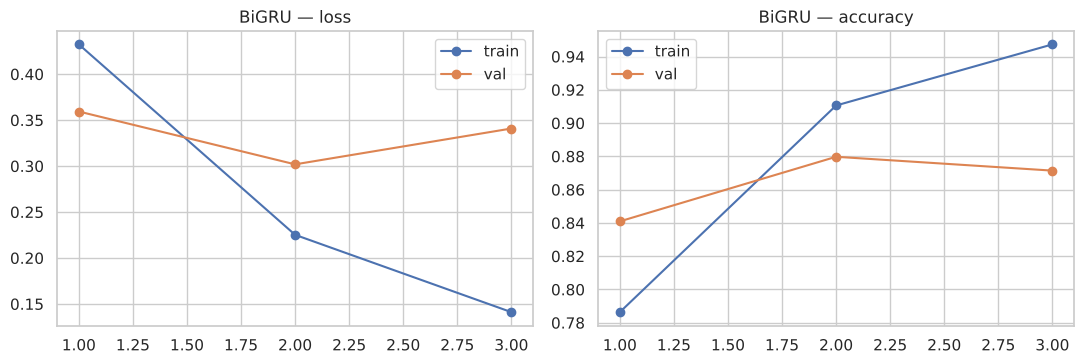

In [25]:
plot_hist(hC,'BiGRU')

In [26]:
report('C · BiGRU', mC, hC)

accuracy     8.911000e-01
f1           8.926000e-01
roc_auc      9.552000e-01
params       3.064001e+06
train_sec    1.361708e+03
dtype: float64

## 7. Compare all deep models with the classical baseline

In [27]:
res = pd.DataFrame(TEST_RESULTS).T
try:
    cl = pd.read_csv('data/classical_results.csv', index_col=0); res.loc['★ best classical (TF-IDF 1-2gram)'] = dict(accuracy=cl.accuracy.max(), f1=cl.loc[cl.accuracy.idxmax(),'f1'], roc_auc=cl.loc[cl.accuracy.idxmax(),'roc_auc'], params=np.nan, train_sec=cl.loc[cl.accuracy.idxmax(),'train_sec'])
except FileNotFoundError: print('run notebook 05 first for the classical baseline')
res.sort_values('accuracy', ascending=False).round(4)

,accuracy,f1,roc_auc,params,train_sec
★ best classical (TF-IDF 1-2gram),0.9172,0.9183,0.9735,NaN,1.4068
A · AvgEmbed,0.8913,0.8910,0.9560,1920065.0,40.0622
C · BiGRU,0.8911,0.8926,0.9552,3064001.0,1361.7083
B · TextCNN,0.8756,0.8735,0.9491,3090113.0,393.4574


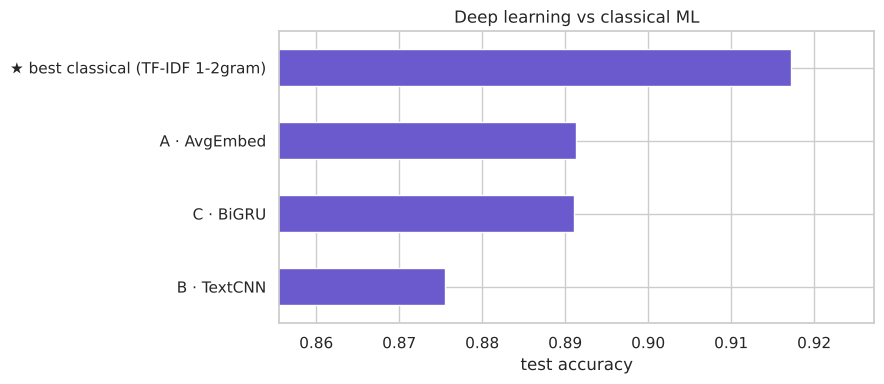

In [28]:
res['accuracy'].sort_values().plot(kind='barh', color='slateblue', figsize=(9,4)); plt.xlim(res.accuracy.min()-.02, res.accuracy.max()+.01); plt.xlabel('test accuracy'); plt.title('Deep learning vs classical ML'); plt.tight_layout(); plt.show()

## 8. Detailed look at the best neural model

In [29]:
best_name = pd.DataFrame(TEST_RESULTS).T['accuracy'].idxmax(); best_model = {'A':mA,'B':mB,'C':mC}[best_name[0]]; print('best neural model:', best_name)
lg = predict_logits(best_model); pred=(lg>0).astype(int); y=Y['test'].numpy()
print(classification_report(y, pred, target_names=['negative','positive'], digits=4))

best neural model: A · AvgEmbed
              precision    recall  f1-score   support

    negative     0.8859    0.8974    0.8916      4940
    positive     0.8968    0.8853    0.8910      4977

    accuracy                         0.8913      9917
   macro avg     0.8913    0.8913    0.8913      9917
weighted avg     0.8914    0.8913    0.8913      9917



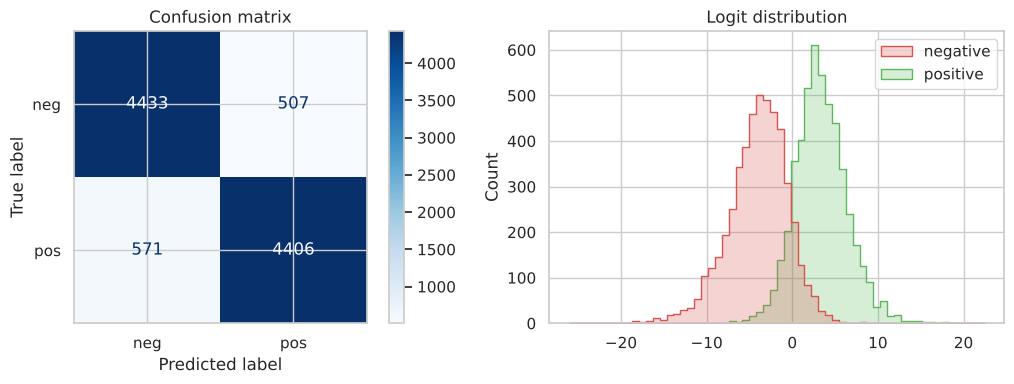

In [30]:
fig,ax=plt.subplots(1,2,figsize=(11,4)); ConfusionMatrixDisplay.from_predictions(y,pred,display_labels=['neg','pos'],cmap='Blues',ax=ax[0]); ax[0].set_title('Confusion matrix')
sns.histplot(x=lg, hue=np.where(y==1,'positive','negative'), bins=60, palette={'negative':'#d9534f','positive':'#5cb85c'}, element='step', ax=ax[1]); ax[1].set_title('Logit distribution'); plt.tight_layout(); plt.show()

In [31]:
tdf = df.loc[test_idx].copy(); tdf['logit']=lg; tdf['pred']=pred; tdf['n_words']=tdf.clean.str.split().str.len(); tdf['ok']=tdf.pred==tdf.label
tdf.groupby(pd.cut(tdf.n_words,[0,100,200,256,400,3000]))['ok'].agg(['mean','count']).round(4)

,mean,count
n_words,,
"(0, 100]",0.9064,1250
"(100, 200]",0.9009,4552
"(200, 256]",0.9062,1268
"(256, 400]",0.8692,1499
"(400, 3000]",0.8553,1348


Accuracy by length shows the cost of truncating at 256 tokens: very long reviews lose their ending, where verdicts often live.

In [32]:
w = tdf[~tdf.ok].assign(a=lambda d: d.logit.abs()).sort_values('a', ascending=False).head(3)
for _,r in w.iterrows(): print(f'TRUE={r.sentiment} logit={r.logit:.2f}\n{r.review[:400]}\n{"-"*70}')

TRUE=negative logit=22.35
More suspenseful, more subtle, much, much more disturbing....
----------------------------------------------------------------------
TRUE=positive logit=-10.42
black tar can't be snorted there's a documentary: dark end of the street about s.f. street punks and b.t. abuse - not bad - quite heavy. in wasted there's this stuff that looks like coke but should be something else... no big deal. black tar can't be snorted there's a documentary: dark end of the street about s.f. street punks and b.t. abuse - not bad - quite heavy. in wasted there's this stuff th
----------------------------------------------------------------------
TRUE=positive logit=-9.74
It's not Citizen Kane, but it does deliver. Cleavage, and lots of it.<br /><br />Badly acted and directed, poorly scripted. Who cares? I didn't watch it for the dialog.
----------------------------------------------------------------------


## 9. Agreement between neural and classical models

In [33]:
import joblib
pipe = joblib.load('models/tfidf_logreg_pipeline.pkl'); cp = pipe.predict(df.loc[test_idx,'clean'])
agree = (cp==pred).mean(); both_right = ((cp==y)&(pred==y)).mean(); both_wrong=((cp!=y)&(pred!=y)).mean()
pd.Series({'agree on label':agree,'both correct':both_right,'both wrong':both_wrong,'only classical correct':((cp==y)&(pred!=y)).mean(),'only neural correct':((cp!=y)&(pred==y)).mean()}).round(4).to_frame('share of test set')

,share of test set
agree on label,0.9259
both correct,0.8668
both wrong,0.0591
only classical correct,0.0496
only neural correct,0.0245


In [34]:
ens_logit = (lg/np.std(lg)) + (pipe.decision_function(df.loc[test_idx,'clean'])/np.std(pipe.decision_function(df.loc[test_idx,'clean'])))
print('Simple ensemble (neural + TF-IDF LR) accuracy:', round(accuracy_score(y,(ens_logit>0).astype(int)),4))

Simple ensemble (neural + TF-IDF LR) accuracy: 0.9128


Only ~5% of test reviews are right for the classical model but wrong for the neural one (and ~2.5% the reverse), so the models do make different mistakes. Yet the simple averaged ensemble (**91.28%**) did *not* beat the classical model alone (91.6–91.7%) — the weaker neural model drags it down. Ensembling only helps when the members are about equally strong.

## 10. Inspect what the embeddings learned

In [35]:
E = mA.emb.weight.detach().numpy(); E_n = E/np.linalg.norm(E,axis=1,keepdims=True).clip(1e-9)
def nearest(w,k=8):
    if w not in stoi: return None
    sims=E_n@E_n[stoi[w]]; return [itos[i] for i in sims.argsort()[::-1][1:k+1]]
for w in ['great','terrible','boring','amazing','waste']: print(w,'→',nearest(w))

great → ['refreshing', 'dismissed', 'astonishing', 'brilliant', 'desolate', 'gershwin', 'believable', 'musicians']
terrible → ['pretentious', 'worst', 'worse', 'waste', 'fails', 'disappointing', 'pathetic', 'awful']
boring → ['awful', 'forgettable', 'horrible', 'pathetic', 'worst', 'waste', 'pretentious', 'terrible']
amazing → ['today', 'hilarious', 'refreshing', 'swim', 'excellent', 'perfect', 'outstanding', 'wonderfully']
waste → ['worst', 'awful', 'disappointing', 'pathetic', 'terrible', 'poorly', 'fails', 'pretentious']


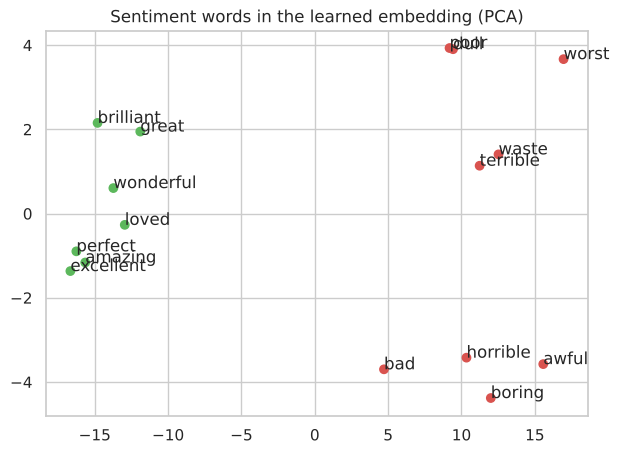

In [36]:
from sklearn.decomposition import PCA
words = ['great','excellent','wonderful','amazing','brilliant','loved','perfect','awful','terrible','horrible','worst','boring','bad','waste','poor','dull']
words=[w for w in words if w in stoi]; P=PCA(2).fit_transform(E[[stoi[w] for w in words]])
plt.figure(figsize=(7,5)); colors=['#5cb85c' if i<7 else '#d9534f' for i in range(len(words))]
plt.scatter(P[:,0],P[:,1],c=colors)
for (x_,y_),w in zip(P,words): plt.annotate(w,(x_,y_))
plt.title('Sentiment words in the learned embedding (PCA)'); plt.show()

## 11. Predict on new text

In [37]:
def encode_raw(t): return encode(re.sub(r'\s+',' ', re.sub(r'[^a-z\s]',' ', re.sub(r'<[^>]+>',' ', t.lower().replace("n't",' not')))).strip())
@torch.no_grad()
def predict_text(t, model=None):
    model=model or best_model; model.eval(); p=torch.sigmoid(model(torch.tensor([encode_raw(t)]))).item(); return ('positive' if p>.5 else 'negative', round(p,3))
for s in ['One of the best films of the decade, I loved it!','Dull, slow and a complete waste of time.','It was not good.','Not bad at all, I enjoyed it.','The acting was great but the story was a mess.']: print(predict_text(s), '←', s)

('positive', 1.0) ← One of the best films of the decade, I loved it!
('negative', 0.0) ← Dull, slow and a complete waste of time.
('positive', 0.961) ← It was not good.
('positive', 0.61) ← Not bad at all, I enjoyed it.
('negative', 0.001) ← The acting was great but the story was a mess.


## 12. Save the model and vocabulary

In [38]:
import json; os.makedirs('models', exist_ok=True)
torch.save(best_model.state_dict(), 'models/best_neural_sentiment.pt')
json.dump({'itos':itos,'max_len':MAX_LEN,'model':best_name}, open('models/vocab.json','w'))
print(round(os.path.getsize('models/best_neural_sentiment.pt')/1e6,1),'MB')

7.7 MB


In [39]:
pd.DataFrame(TEST_RESULTS).T.to_csv('data/deep_results.csv'); print('saved')

saved


## 13. Summary & honest conclusions
| Model | Test accuracy | Training time (CPU) |
|---|---|---|
| A · AvgEmbed (fastText-style) | 89.13% | 40 s |
| B · TextCNN | 87.56% | 6.6 min |
| C · BiGRU | 89.11% | 22.7 min |
| ★ Best classical: TF-IDF 1–2-gram + LinearSVC (notebook 05) | **91.72%** | seconds |

- **The simple classical model won.** On 40k training reviews and small CPU-sized networks, TF-IDF + a linear model beat all three neural nets by ~2.5 points and trained far faster.
- A weakness to note: the best neural model (AvgEmbed) ignores word order, so it labels *"It was not good."* as positive (see §11). The TF-IDF bigram model handles that case better.
- Deep learning usually pulls ahead only with **pre-trained language models** (e.g. fine-tuned DistilBERT, typically ≈ 92–94% on IMDB), which need a GPU and a model download — not possible in this CPU run.

### Where to go next
1. Fine-tune a pre-trained transformer on a GPU (Colab / Kaggle).
2. Serve the best model in a small Streamlit / FastAPI app.
3. Try the same pipeline on another review dataset (Amazon, Yelp).